In [1]:
import sys

!which {sys.executable}

/ut3/jerome/miniconda3/envs/wakai/bin/python


In [2]:
import sys
sys.path.insert(0, '..')

# cross-match Roth+2026 PC with GaiaDR3

In [3]:
from astropy.table import Table
import astropy.io.ascii as ascii

url="https://content.cld.iop.org/journals/0067-0049/284/1/19/revision3/apjsae5b6ct1_mrt.txt"
tab = Table.read(url, format='ascii.mrt')
df_pc = tab.to_pandas()
df_pc

Error.  nthreads cannot be larger than environment variable "NUMEXPR_MAX_THREADS" (60)

,GAIAID,TICID,Sector,Cam,CCD,Teff,Lstar,Rstar,Mstar,Tmag,...,q1,e_q1,E_q1,q2,e_q2,E_q2,S/PN,Ntransits,RAdeg,DEdeg
0,6483087867267625344,126747090,1,1,1,5656.623535,0.881520,0.947000,0.951421,12.52544,...,0.42,3.000000e-01,3.700000e-01,0.43,3.000000e-01,3.700000e-01,15.331,5.0,315.958591,-46.940260
1,6483211012570211840,126745699,1,1,1,4764.170898,0.348844,0.894800,0.760000,13.78529,...,0.54,3.400000e-01,3.200000e-01,0.54,3.600000e-01,3.200000e-01,13.484,3.0,315.763322,-45.956550
2,6483399338295808512,126704293,1,1,1,5040.000000,0.318267,0.739925,0.840000,13.84042,...,0.44,3.100000e-01,3.700000e-01,0.46,3.200000e-01,3.600000e-01,11.173,3.0,315.495903,-45.873851
3,6483491731632469120,126639627,1,1,1,5203.993164,0.785871,0.988000,0.901182,15.71073,...,0.50,1.190000e-07,9.900000e-08,0.50,4.400000e-08,1.300000e-07,12.167,3.0,314.858629,-45.181716
4,6484998406159908992,91449277,1,1,1,5052.906738,0.443564,0.778300,0.850000,14.48518,...,0.35,2.600000e-01,4.100000e-01,0.38,2.700000e-01,3.800000e-01,15.998,6.0,313.749579,-43.255488
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11138,4758770373231761152,149929808,13,4,4,5767.964355,2.583816,1.533000,1.055473,13.46701,...,0.61,3.600000e-01,2.800000e-01,0.63,3.900000e-01,2.700000e-01,18.409,2.0,89.596483,-60.835807
11139,4762911202740967424,358459069,13,4,4,5728.452637,1.051754,0.884500,0.970137,15.00149,...,0.56,3.400000e-01,3.000000e-01,0.58,3.800000e-01,3.000000e-01,14.279,11.0,78.101981,-59.142541
11140,4764734364818096896,220479919,13,4,4,5442.893555,0.905910,1.069800,1.010000,13.08563,...,0.51,3.400000e-01,3.300000e-01,0.51,3.500000e-01,3.300000e-01,23.003,5.0,75.948508,-54.915350
11141,4765029922992281600,350742160,13,4,4,5588.127441,1.629779,1.347300,0.941585,12.54204,...,0.46,3.200000e-01,3.600000e-01,0.49,3.300000e-01,3.400000e-01,10.089,3.0,88.659738,-58.970089


In [10]:
df_pc['TIC'] = df_pc.TICID.copy()

In [13]:
df_pc.columns

Index(['GAIAID', 'TICID', 'Sector', 'Cam', 'CCD', 'Teff', 'Lstar', 'Rstar',
       'Mstar', 'Tmag', 'mh-gspphot', 'qtran', 'qingress', 'P', 'e_P', 'E_P',
       'Tc', 'e_Tc', 'E_Tc', 'a/Rs', 'e_a/Rs', 'E_a/Rs', 'rp/rs', 'e_rp/rs',
       'E_rp/rs', 'b', 'e_b', 'E_b', 'q1', 'e_q1', 'E_q1', 'q2', 'e_q2',
       'E_q2', 'S/PN', 'Ntransits', 'RAdeg', 'DEdeg', 'TIC', 'ID', 'GAIA',
       'ra', 'dec', 'plx', 'pmRA', 'pmDEC'],
      dtype='object')

## match 3d separation with cluster core

In [4]:
from astroquery.mast import Catalogs
import numpy as np

# Query the TIC catalog for these IDs
# We specifically want the 'GAIA' column which contains the Gaia DR2/DR3 source_id
tic_data = Catalogs.query_criteria(catalog="TIC", ID=df_pc['TIC'].unique())

In [11]:
import pandas as pd

df_gaia = tic_data.to_pandas()[['ID','GAIA','ra','dec','plx','pmRA','pmDEC']].astype(float)
df_gaia['TIC'] = df_gaia.ID.copy()
df_pc = pd.merge(df_pc, df_gaia, on='TIC')
df_pc.shape

(11143, 46)

In [14]:
from astroquery.gaia import Gaia

# Extract unique Gaia IDs and remove masked/null values
gaia_ids = [int(gid) for gid in tic_data['GAIA'] if gid is not np.ma.masked]

# Format the IDs for the SQL 'IN' clause
ids_str = ",".join(map(str, gaia_ids))

# ADQL query to get source_id and radial_velocity
query = f"""
SELECT source_id, radial_velocity, radial_velocity_error
FROM gaiadr3.gaia_source
WHERE source_id IN ({ids_str})
"""

# Launch the job
job = Gaia.launch_job_async(query)
results = job.get_results()

INFO: Query finished. [astroquery.utils.tap.core]


In [15]:
df_rv = results.to_pandas().astype(float).rename({
    'SOURCE_ID': 'GAIA',
    }, axis=1
                                  )
df_pc = pd.merge(df_pc, df_rv, on='GAIA')

In [16]:
df_pc = df_pc.rename({
        "GAIA": "GaiaDR3",
        "pmRA": "pmra",
        "pmDEC": "pmdec",
        "plx": "parallax",
        "RV": "radial_velocity"
        
    }, axis=1)
df_pc.head()

,GAIAID,TICID,Sector,Cam,CCD,Teff,Lstar,Rstar,Mstar,Tmag,...,TIC,ID,GaiaDR3,ra,dec,parallax,pmra,pmdec,radial_velocity,radial_velocity_error
0,6483087867267625344,126747090,1,1,1,5656.623535,0.881520,0.947000,0.951421,12.52544,...,126747090,126747090.0,6.483088e+18,315.958561,-46.940300,2.273930,4.64142,9.11795,18.505302,1.713068
1,6483211012570211840,126745699,1,1,1,4764.170898,0.348844,0.894800,0.760000,13.78529,...,126745699,126745699.0,6.483211e+18,315.763281,-45.956544,2.130150,6.31932,-1.22462,-1.195082,4.085058
2,6483399338295808512,126704293,1,1,1,5040.000000,0.318267,0.739925,0.840000,13.84042,...,126704293,126704293.0,6.483399e+18,315.495828,-45.873733,2.142850,11.69220,-26.54610,21.011375,7.374191
3,6483491731632469120,126639627,1,1,1,5203.993164,0.785871,0.988000,0.901182,15.71073,...,126639627,126639627.0,6.483492e+18,314.858608,-45.181697,0.497825,3.33800,-4.27947,NaN,NaN
4,6484998406159908992,91449277,1,1,1,5052.906738,0.443564,0.778300,0.850000,14.48518,...,91449277,91449277.0,6.484998e+18,313.749489,-43.255428,1.268460,14.70270,-13.36320,NaN,NaN


# Perren+2023 catalog

In [17]:
import pandas as pd

catalog_name = 'Perren2023'
df = pd.read_csv('../data/Perren2023/UCC_cat.csv')
df.tail()

,Name(s),name,N_50,r_50,RA_ICRS,DE_ICRS,GLON,GLAT,Plx,pmRA,...,Mass_[Msun],Mass_STDDEV,Binary_fr,Binary_fr_STDDEV,BSS,BSS_STDDEV,C3,P_dup,UTI,bad_oc
18264,XDOCC 10,xdocc10,23.0,7.4,305.52488,37.23809,75.66132,0.15836,0.5007,-2.4023,...,655.0,NaN,0.29,NaN,NaN,NaN,AA,0.0,0.25,n
18265,XDOCC 11,xdocc11,54.0,4.3,317.73684,47.70377,89.41856,-0.28394,0.4536,-1.0068,...,591.0,NaN,0.29,NaN,NaN,NaN,AB,0.8,0.09,n
18266,Zanin 6,zanin6,24.0,39.4,342.91235,41.33289,99.92967,-16.14552,2.6838,5.9365,...,NaN,NaN,NaN,NaN,NaN,NaN,DC,0.0,0.08,y
18267,Zeta Gemini,zetagemini,19.0,8.0,105.96593,20.56051,195.72326,11.87995,0.2679,-0.7368,...,NaN,NaN,NaN,NaN,NaN,NaN,BC,0.0,0.09,y
18268,ZHBJZ 1,zhbjz1,243.0,47.5,103.73696,-5.89465,218.61444,-1.85052,3.4866,-7.4140,...,282.0,166.0,NaN,NaN,NaN,NaN,AA,1.0,0.00,n


In [18]:
df = df.rename({"name": "Name",
                #"Source": "GaiaDR3",
                "probs": "Prob",
                "RA_ICRS": "ra",
                "DE_ICRS": "dec",
                "pmRA": "pmra",
                "pmDE": "pmdec",
                "Plx": "parallax",
                "RV": "radial_velocity"
                }, axis=1)

In [19]:
df_mem = pd.read_parquet('../data/Perren2023/UCC_members.parquet')
df_mem.tail()

,name,Source,RA_ICRS,DE_ICRS,Plx,e_Plx,pmRA,e_pmRA,pmDE,e_pmDE,RV,e_RV,GLON,GLAT,Gmag,BP-RP,e_Gmag,e_BP-RP,probs
1095681,zhbjz1,3101181101717965312,104.13589,-5.48616,3.4796,0.0468,-7.6025,0.0414,-2.4144,0.0409,NaN,NaN,218.39623,-1.36721,15.6225,2.8157,0.0029,0.0131,1.000
1095682,zhbjz1,3100956320310482048,104.53184,-5.89465,3.5259,0.0222,-7.7372,0.0278,-2.5817,0.0294,16.6076,5.3441,218.93959,-1.20291,14.2556,1.7210,0.0031,0.0085,1.000
1095683,zhbjz1,3101226185994403968,103.65533,-5.53413,3.5530,0.0537,-7.2244,0.0599,-2.6371,0.0526,NaN,NaN,218.22092,-1.81488,16.4796,2.7865,0.0038,0.0253,1.000
1095684,zhbjz1,3101094072800870400,103.15896,-5.98809,3.6033,0.1457,-7.2640,0.1371,-2.6682,0.1321,NaN,NaN,218.40071,-2.46118,17.4554,3.3142,0.0032,0.0574,0.921
1095685,zhbjz1,3100740511096457984,104.27646,-6.89400,3.3414,0.0949,-7.2711,0.0969,-2.0291,0.0745,NaN,NaN,219.71357,-1.88447,17.2505,2.8632,0.0030,0.0292,0.843


In [20]:
#replace name to be compatible with other catalogs' naming formats
df_mem = df_mem.rename({"name": "Name",
                        "Source": "GaiaDR3",
                        "probs": "Prob",
                        "RA_ICRS": "ra",
                        "DE_ICRS": "dec",
                        "pmRA": "pmra",
                        "pmDE": "pmdec",
                        "Plx": "parallax",
                        "RV": "radial_velocity"
                        }, axis=1)
df_mem.shape

(1095686, 19)

In [21]:
idx = df_mem.GaiaDR3.isin(df_pc.GaiaDR3)
idx.sum()

np.int64(52)

In [41]:
idx = df_pc.GaiaDR3.isin(df_mem.GaiaDR3)
df_pc[idx].shape

(43, 50)

In [42]:
df_pc[idx]

,GAIAID,TICID,Sector,Cam,CCD,Teff,Lstar,Rstar,Mstar,Tmag,...,GaiaDR3,ra,dec,parallax,pmra,pmdec,radial_velocity,radial_velocity_error,sep2d_arcsec,sep3d_pc
1194,3213676641777242240,248441670,5,1,2,3479.155762,0.134894,0.97330,0.644616,15.11045,...,3.213677e+18,77.612185,-3.683680,2.899470,0.067555,-0.877752,NaN,NaN,577.929521,1.697095
1651,3217201126300537344,50727367,6,1,1,4124.123535,0.353965,1.17700,0.640000,13.83248,...,3.217201e+18,82.833287,-1.781495,2.399260,0.202689,-0.213062,22.077448,5.283858,1099.031950,2.384308
1654,3218615166972886016,39291805,6,1,1,5686.173340,1.039759,0.72840,0.953164,15.33454,...,3.218615e+18,88.716434,-0.048451,0.896388,-3.442740,4.328090,NaN,NaN,1890.789216,19.634431
1748,3113360842997689344,237610059,6,1,2,4814.071289,0.294681,0.82060,0.778936,15.31358,...,3.113361e+18,103.327976,0.070889,1.110560,-1.549240,-2.176600,NaN,NaN,968.718418,720.846790
1832,3129708965991892224,235541554,6,1,3,7082.597168,3.144814,1.16460,1.380000,15.57278,...,3.129709e+18,104.525281,6.328490,0.291382,-0.922448,0.911936,NaN,NaN,389.274498,177.009151
2005,3334809597291914880,284200852,6,1,4,6001.509277,2.740055,1.48350,1.118384,13.12066,...,3.334810e+18,84.415237,8.951459,2.422110,1.279440,-2.622210,25.292347,4.212772,3562.262628,12.385842
2015,3339440121793155840,436331727,6,1,4,3962.000000,0.304871,1.17188,0.620000,14.07297,...,3.339440e+18,84.239598,9.890515,2.497000,0.963838,-2.254140,25.350857,8.393349,1432.530769,4634.776643
2101,2967096350203293184,93208171,6,2,1,4173.682617,0.107651,0.63640,0.649931,14.43096,...,2.967096e+18,85.445922,-19.258110,3.290450,-6.926000,1.506730,26.034689,6.510057,1603.711650,190.846790
2188,2950834160912881920,443537526,6,2,3,5676.330078,1.366925,0.71050,0.951647,14.90579,...,2.950834e+18,99.153190,-14.157665,0.651619,-0.034175,-1.110510,NaN,NaN,185.276742,5.882666
2261,2991330170594739200,318061283,6,2,4,3469.912109,0.044073,0.52690,0.528110,16.05194,...,2.991330e+18,90.207997,-16.866251,3.532860,-5.204610,6.215970,NaN,NaN,2542.559746,14.155277


In [53]:
from wakai.catalog import get_tois

tois = get_tois()
idx2 = df_pc.loc[idx,'TIC'].isin(tois['TIC ID'])
df_pc[idx][~idx2]

,GAIAID,TICID,Sector,Cam,CCD,Teff,Lstar,Rstar,Mstar,Tmag,...,GaiaDR3,ra,dec,parallax,pmra,pmdec,radial_velocity,radial_velocity_error,sep2d_arcsec,sep3d_pc
1194,3213676641777242240,248441670,5,1,2,3479.155762,0.134894,0.97330,0.644616,15.11045,...,3.213677e+18,77.612185,-3.683680,2.899470,0.067555,-0.877752,NaN,NaN,577.929521,1.697095
1651,3217201126300537344,50727367,6,1,1,4124.123535,0.353965,1.17700,0.640000,13.83248,...,3.217201e+18,82.833287,-1.781495,2.399260,0.202689,-0.213062,22.077448,5.283858,1099.031950,2.384308
1654,3218615166972886016,39291805,6,1,1,5686.173340,1.039759,0.72840,0.953164,15.33454,...,3.218615e+18,88.716434,-0.048451,0.896388,-3.442740,4.328090,NaN,NaN,1890.789216,19.634431
1748,3113360842997689344,237610059,6,1,2,4814.071289,0.294681,0.82060,0.778936,15.31358,...,3.113361e+18,103.327976,0.070889,1.110560,-1.549240,-2.176600,NaN,NaN,968.718418,720.846790
1832,3129708965991892224,235541554,6,1,3,7082.597168,3.144814,1.16460,1.380000,15.57278,...,3.129709e+18,104.525281,6.328490,0.291382,-0.922448,0.911936,NaN,NaN,389.274498,177.009151
2005,3334809597291914880,284200852,6,1,4,6001.509277,2.740055,1.48350,1.118384,13.12066,...,3.334810e+18,84.415237,8.951459,2.422110,1.279440,-2.622210,25.292347,4.212772,3562.262628,12.385842
2015,3339440121793155840,436331727,6,1,4,3962.000000,0.304871,1.17188,0.620000,14.07297,...,3.339440e+18,84.239598,9.890515,2.497000,0.963838,-2.254140,25.350857,8.393349,1432.530769,4634.776643
2101,2967096350203293184,93208171,6,2,1,4173.682617,0.107651,0.63640,0.649931,14.43096,...,2.967096e+18,85.445922,-19.258110,3.290450,-6.926000,1.506730,26.034689,6.510057,1603.711650,190.846790
2188,2950834160912881920,443537526,6,2,3,5676.330078,1.366925,0.71050,0.951647,14.90579,...,2.950834e+18,99.153190,-14.157665,0.651619,-0.034175,-1.110510,NaN,NaN,185.276742,5.882666
2261,2991330170594739200,318061283,6,2,4,3469.912109,0.044073,0.52690,0.528110,16.05194,...,2.991330e+18,90.207997,-16.866251,3.532860,-5.204610,6.215970,NaN,NaN,2542.559746,14.155277


In [24]:
from astropy.coordinates import SkyCoord, Distance
import astropy.units as u

coords1 = SkyCoord(ra=df_pc['ra'].values*u.degree, 
                   dec=df_pc['dec'].values*u.degree, 
                   distance=Distance(parallax=df_pc['parallax'].values* u.mas, allow_negative=True),
                   frame='icrs')
coords2 = SkyCoord(ra=df['ra'].values*u.degree, 
                   dec=df['dec'].values*u.degree, 
                   distance=Distance(parallax=df['parallax'].values* u.mas, allow_negative=True),
                   frame='icrs') 

idx, d2d, d3d = coords1.match_to_catalog_sky(coords2)

df_pc['sep2d_arcsec'] = d2d.to(u.arcsec).value
df_pc['sep3d_pc'] = d3d.to(u.pc).value
df_pc.sort_values('sep2d_arcsec').head()

,GAIAID,TICID,Sector,Cam,CCD,Teff,Lstar,Rstar,Mstar,Tmag,...,GaiaDR3,ra,dec,parallax,pmra,pmdec,radial_velocity,radial_velocity_error,sep2d_arcsec,sep3d_pc
3836,3051294717279272704,177447293,7,2,4,4421.091797,0.154392,0.707100,0.711612,15.75330,...,3.051295e+18,106.874284,-8.934022,1.56385,-4.95639,-6.686360,NaN,NaN,4.964034,1334.886145
3268,5614107303447645056,110249712,7,2,2,4303.029297,0.140111,0.737300,0.679715,15.53931,...,5.614107e+18,114.107929,-26.013932,1.78637,3.68467,12.018100,NaN,NaN,19.264468,3389.652637
8264,5869878000462100096,359533680,11,2,2,3647.000000,0.034766,0.467048,0.464565,13.96186,...,5.869878e+18,201.431292,-58.996476,6.77977,-51.38980,12.361900,26.609478,3.437628,21.926767,3234.308256
6154,5519936400269977216,82649580,9,3,2,5320.476074,2.184170,1.704000,0.990251,12.47385,...,5.519936e+18,124.873529,-45.272266,1.47205,-14.44540,11.934400,85.489143,2.447230,35.092164,2504.374720
7419,6054256033009679232,379126375,10,3,1,6913.323242,10.159267,2.415500,1.639732,12.14518,...,6.054256e+18,180.871381,-63.864037,0.96955,-14.86110,0.089209,-12.860452,35.075233,35.417189,5689.023803


In [25]:
import sys
sys.path.insert(0, '..')
from wakai.catalog import get_cluster_3d_size

# test on praesepe
d = df_mem.groupby('Name').get_group('ic2602')
get_cluster_3d_size(d)

np.float64(56.72352784737517)

In [26]:
# apply func to all clusters
df_size = df_mem.groupby('Name').apply(get_cluster_3d_size)

/ut3/jerome/miniconda3/envs/wakai/lib/python3.12/site-packages/astropy/units/equivalencies.py:100: RuntimeWarning: divide by zero encountered in divide
  d = 1 / x
/tmp/ipykernel_1160909/3100306159.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_size = df_mem.groupby('Name').apply(get_cluster_3d_size)


In [27]:
df = df.merge(df_size.reset_index(name='extent_pc'), on='Name')
df.head()

,Name(s),Name,N_50,r_50,ra,dec,GLON,GLAT,parallax,pmra,...,Mass_STDDEV,Binary_fr,Binary_fr_STDDEV,BSS,BSS_STDDEV,C3,P_dup,UTI,bad_oc,extent_pc
0,ADS 12696,ads12696,11.0,6.7,294.31735,29.33689,64.00852,3.97490,0.1604,-2.4837,...,NaN,NaN,NaN,NaN,NaN,DC,0.00,0.03,y,13562.040379
1,ADS 13292,ads13292,83.0,1.0,300.59778,35.31288,71.86015,2.42440,0.5153,-3.3527,...,NaN,NaN,NaN,NaN,NaN,AB,0.24,0.37,n,1932.852329
2,ADS 16795;AR Cas,ads16795,25.0,88.7,351.39010,58.44167,111.87712,-2.57522,4.4213,19.1632,...,NaN,NaN,NaN,NaN,NaN,CC,0.00,0.18,y,47.716982
3,AFGL333,afgl333,21.0,6.9,37.28676,61.47758,134.31242,0.77933,0.4389,-1.1749,...,NaN,NaN,NaN,NaN,NaN,BB,0.00,0.14,y,1600.637192
4,AFGL4029,afgl4029,30.0,3.9,45.20529,60.54280,138.20570,1.56202,0.4398,-0.1279,...,NaN,NaN,NaN,NaN,NaN,DC,0.47,0.14,n,1374.376330


In [28]:
# Add a prefix to matched columns to avoid confusion (optional but recommended)
col_prefix = 'matched_'
df_matched_tic = df.iloc[idx].copy().add_prefix(col_prefix)

# Concatenate horizontally
df_match = pd.concat([df_pc.reset_index(drop=True), 
                      df_matched_tic.reset_index(drop=True)
                      ], axis=1)

In [29]:
# make sure the 3d sep from cluster core is smaller the spatial extent of that cluster
idx2 = df_match[f'{col_prefix}extent_pc'] > df_match['sep3d_pc']
df_match[idx2]

,GAIAID,TICID,Sector,Cam,CCD,Teff,Lstar,Rstar,Mstar,Tmag,...,matched_Mass_STDDEV,matched_Binary_fr,matched_Binary_fr_STDDEV,matched_BSS,matched_BSS_STDDEV,matched_C3,matched_P_dup,matched_UTI,matched_bad_oc,matched_extent_pc
38,6547524918010470912,214660504,1,1,2,5126.502930,0.891862,1.210900,0.884329,11.36379,...,NaN,NaN,NaN,NaN,NaN,CB,0.0,0.10,y,43.331830
56,6601336322743396736,270566704,1,1,2,3393.981689,0.036424,0.529300,0.447784,15.43993,...,NaN,NaN,NaN,NaN,NaN,CB,0.0,0.10,y,43.331830
96,6828056651183860992,99743436,1,1,3,3912.000000,0.103581,0.700641,0.663944,13.52324,...,NaN,NaN,NaN,NaN,NaN,CA,0.0,0.29,n,62.011263
98,6779308394419726848,441422655,1,1,4,4665.293945,0.257467,0.832600,0.740000,14.56477,...,NaN,NaN,NaN,NaN,NaN,DC,0.0,0.04,y,282.515899
117,6400608517905868544,419636038,1,2,1,5132.123535,0.775450,0.983600,0.920000,14.93503,...,NaN,NaN,NaN,NaN,NaN,BB,0.0,0.19,y,419.455907
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11071,5486883637618233344,293971461,13,4,3,5524.025879,1.006308,1.035800,0.905907,15.15497,...,NaN,NaN,NaN,NaN,NaN,CC,0.0,0.08,y,4783.254000
11072,5486883843776661248,293971456,13,4,3,4213.149414,0.142083,0.709700,0.645359,15.55977,...,NaN,NaN,NaN,NaN,NaN,CC,0.0,0.08,y,4783.254000
11073,5497248557638218624,279154795,13,4,3,5973.559570,1.382504,1.051700,1.053303,12.43413,...,NaN,0.63,NaN,NaN,NaN,AA,0.0,0.54,n,191.298255
11075,4756003997681009408,374940989,13,4,4,5537.500488,1.104822,1.013900,0.888120,15.48555,...,NaN,NaN,NaN,NaN,NaN,DD,0.0,0.03,y,1401.195733


In [30]:
df_match['pm_diff'] =  np.sqrt((df_match[f'{col_prefix}pmra'] - df_match[f'{col_prefix}pmdec'])**2 + 
                               (df_match['pmra'] - df_match['pmdec'])**2)


In [33]:
idx3 = df_match[idx2]['pm_diff'] < 10
cols = ['TIC','matched_Name','matched_Age_[Myr]',
        'matched_extent_pc','sep3d_pc','pm_diff','GaiaDR3']
df_final = df_match[idx2].loc[idx3,cols]
df_final

,TIC,matched_Name,matched_Age_[Myr],matched_extent_pc,sep3d_pc,pm_diff,GaiaDR3
117,419636038,hsc2721,556.0,419.455907,374.474927,6.663147,6.400609e+18
207,52307665,lisc3704,NaN,1467.290848,1147.235234,2.291545,4.691458e+18
209,38935731,lisc3676,NaN,1273.413543,689.762241,6.526907,4.702761e+18
213,237910706,lisc3704,NaN,1467.290848,1208.627460,2.925330,4.715797e+18
216,299897516,lisc3704,NaN,1467.290848,1265.083953,8.442497,4.903399e+18
...,...,...,...,...,...,...,...
10928,410356603,mwsc4688,2455.0,13333.212654,4019.678369,5.373188,4.611955e+18
11002,389569665,lisc3652,NaN,4052.702048,3156.462551,1.303089,4.659413e+18
11004,373845731,lisc3651,NaN,3485.010647,2221.013936,4.816965,4.660237e+18
11009,55757985,lisc3683,NaN,3558.356576,3219.771377,4.437578,4.662239e+18


In [ ]:
df_final.TIC.apply(lambda x: f'TIC-{x}').tolist()

Coordinate transformation: 'galactic'
Sun(X,Y,Z)=(–8.2, 0, +0.025) kpc
Sun(U,V,W)=(11.1,12.24,7.25) km/s
Coordinate transformation: 'galactic'
Sun(X,Y,Z)=(–8.2, 0, +0.025) kpc
Sun(U,V,W)=(11.1,12.24,7.25) km/s
Plotted 25 stars. Target(s): None


Text(0.5, 0.98, 'TIC-419636038 in hsc2721 (age=556 Myr)')

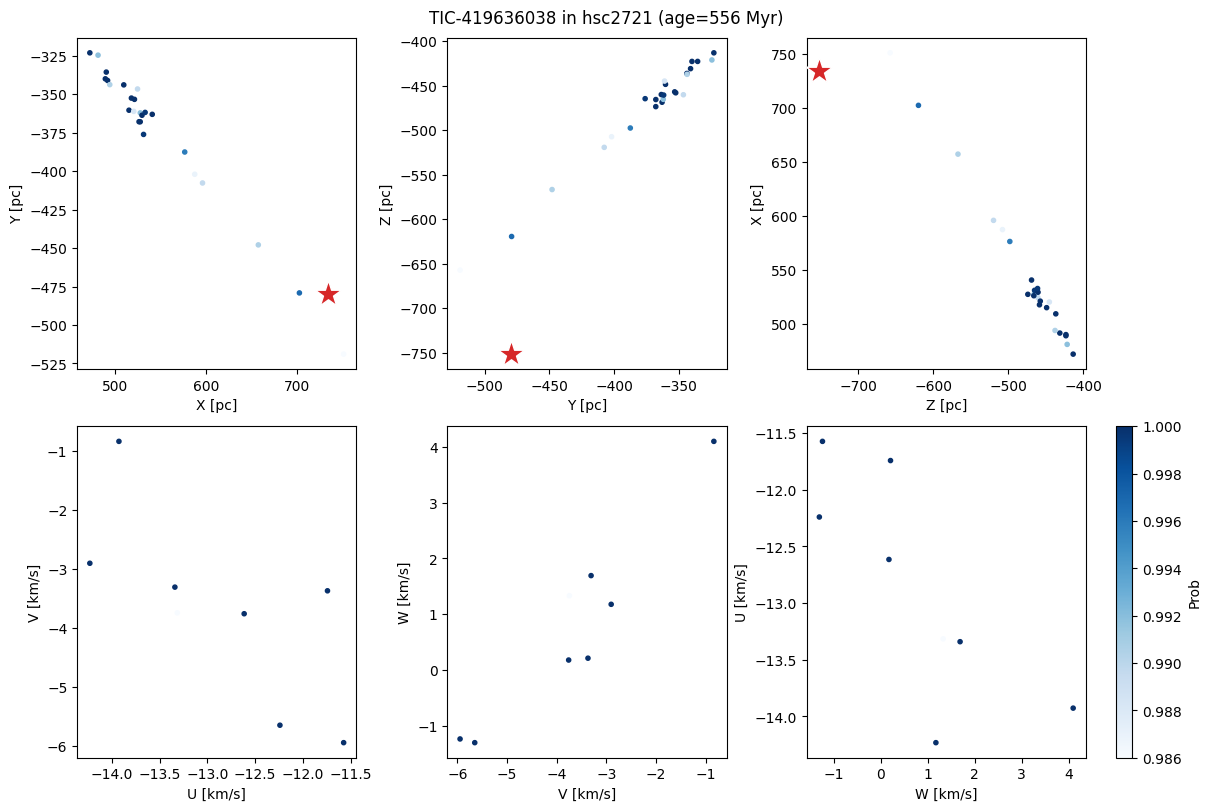

In [35]:
from wakai.catalog import plot_xyz_uvw

n = 0
ticid = df_final["TIC"].values[n]
age = df_final["matched_Age_[Myr]"].values[n]
cname = df_final["matched_Name"].values[n]

df_target = df_match.query("TIC==@ticid").squeeze()
d = df_mem.groupby("Name").get_group(cname)

fig, ax = plot_xyz_uvw(d, 
                       color='Prob', 
                       df_target=df_target,
                       target_color="C3",
                       target_ms=20,
                       marker='.',
                       cmap="Blues");
fig.suptitle(f"TIC-{int(ticid)} in {cname} (age={age:.0f} Myr)")

In [ ]:
import matplotlib.pyplot as pl
from wakai.catalog import plot_rdp_pmrv
from wakai.catalog import plot_xyz_uvw

outdir = '../output/Roth26_pc_near_clusters'
groups = df_mem.groupby("Name")
for i,row in df_final.iterrows():
    try:
        ticid = row.TIC
        df_target = df_match.query("TIC==@ticid").squeeze()
        cname = row["matched_Name"]
        age = row["matched_Age_[Myr]"]
        d = groups.get_group(cname)
        if len(d.radial_velocity.dropna())<10:
            print(f"Skipping TIC {ticid}")
            continue
        fp = f'{outdir}/TIC-{ticid}_in_{cname}_{age:.0f}Myr'
        if False:
            target_gaiaid = row['GaiaDR3']
            fig = plot_rdp_pmrv(d,
                               color='Prob', 
                               target_gaiaid=target_gaiaid,
                               match_id=False,
                               df_target=df_target,
                               target_color="C3",
                               marker='.',
                               cmap="Blues");
            fp=fp+'.png'
        else:
            fig, ax = plot_xyz_uvw(d, 
                               color='Prob', 
                               df_target=df_target,
                               target_color="C3",
                               target_ms=20,
                               marker='.',
                               cmap="Blues",
                               verbose=False
                              );
            fp=fp+'_xyzuvw.png'
        fig.suptitle(f"TIC-{ticid} in {cname} ({age:.0f} Myr)")
        print(f"https://ucc.ar/_clusters/{cname}")
        fig.savefig(fp, bbox_inches='tight', dpi=200)
        # pl.show()
    except Exception as e:
        print(e)